# Classification models with Scikit-learn

## Motivation

In the previous lecture, we studied how to predict continuous variables using linear
models with shrinkage. We now turn to the other common machine learning task,
classification. We study a simplified setting where we have only two classes (labeled 0
and 1) so that the outcome is $y_i \in \{0,1\}$, and we want to train a model to predict
the class membership of observations based on some set of features $\mathbf{x}_i$.

We begin with logistic regression, then study decision trees and random forests. After
fitting and tuning these models, we compare their predictions on an independent test
sample. We conclude the lecture with an optional section on support vector machines
(SVM).

The composable API of scikit-learn makes it easy to try different classifiers
in a processing and estimation pipeline. Nevertheless, each classifier has its own
peculiarities, and we need to account for these differences in feature construction, 
scaling, and hyperparameters:

- Logistic regression uses an index that is linear in its input features. We
   can add polynomial interactions to capture nonlinear relationships.
   Decision trees and random forests, on the other hand, can capture nonlinear relationships
   without this expansion. With SVM, we can select a nonlinear kernel instead
   of adding polynomial features.
- We standardize features for regularized logistic regression and SVM so that
   their scales do not dominate the penalty or distance calculations.
   Decision trees and random forests do not require this scaling.
- Each classifier has its own hyperparameters. We use cross-validation to
   select their values.

***
## Example data for classification

To compare classification methods throughout this lecture, we create an artificial
sample with two features $(x_{1i}, x_{2i})$ that are mapped into a binary outcome
$y_i \in \{0,1\}$. We restrict our attention to only two features since this makes
it easy to plot decision regions.

### Creating a demo dataset

Assume that the data-generating process can be characterized as follows:
$$
y_i = 
\begin{cases}
    1 & \text{if }~ f(x_{1i}, x_{2i}) + \epsilon_i \geq 0 \\
    0 & \text{else} 
\end{cases}
$$
where $f(\bullet)$ is some deterministic function of $(x_{1i}, x_{2i})$ and $\epsilon_i$ is an error term.
For illustration, we'll assume that $f(\bullet)$ is a combination of
trigonometric functions. The data-generating process used throughout
this lecture is
$$
\begin{aligned}
f(x_{1i}, x_{2i}) &= \sin(2\pi x_{1i}) \cos(\pi x_{2i}) \\
\epsilon_i &\stackrel{\text{iid}}{\sim} \mathcal{N}\left(0, \sigma_{\epsilon}^2\right)
\end{aligned}
$$

The code below defines $f(x_{1i}, x_{2i})$:

In [1]:
import numpy as np


def f(x1, x2):
    """
    True function for classification examples
    """
    return np.sin(2 * np.pi * x1) * np.cos(np.pi * x2)

To keep the notebook clean and focused on the main ideas, in this lecture we'll
use a helper module `lecture4_plots.py` which contains most plotting
functions.
To create a contour plot of the true relationship, we import the function `plot_true_relationship()` from this module and pass `f` as its argument.

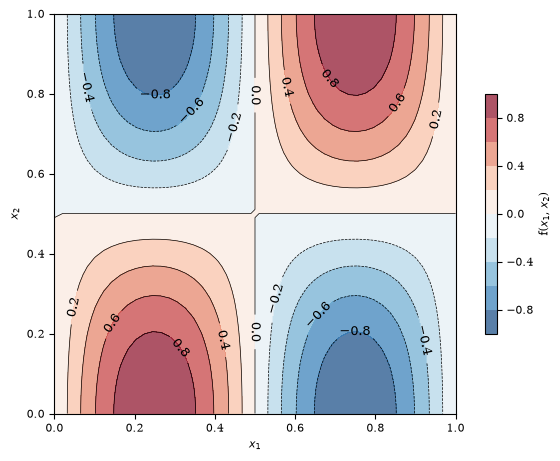

In [2]:
from lecture4_plots import plot_true_relationship

_ = plot_true_relationship(f)

As you see, this function takes on positive values in two quadrants (where $y_i$ would
be 1 without noise) and negative values in the other two (where $y_i$ would be 0 without
noise). Without some noise $\epsilon_i$, class membership would be trivial to predict,
so we next create a sample that incorporates noise.

To do this, we define the function `create_class_data()` which we'll use throughout the lecture to create a demo dataset for classification of the desired size:

In [3]:
def create_class_data(N=100, sigma=0.2, rng=None):
    """
    Create synthetic data for binary classification examples.

    Parameters
    ----------
    N : int
        Number of observations to generate.
    sigma : float
        Standard deviation of the error term.
    rng : numpy.random.Generator, optional
        Random number generator to use.

    Returns
    -------
    X : array-like
        Feature matrix.
    y : array-like
        Binary response variable.

    """

    if rng is None:
        rng = np.random.default_rng(seed=1234)

    # Draw features from uniform distribution
    x1 = rng.uniform(0, 1, size=N)
    x2 = rng.uniform(0, 1, size=N)

    z = f(x1, x2)

    # Add noise to latent variable if noise variance is positive
    if sigma > 0:
        # Draw errors from normal distribution
        epsilon = rng.normal(0, sigma, size=N)
        z += epsilon

    # Convert latent variable to binary response variable with values 0 and 1
    y = (z >= 0).astype(int)

    # Stack features into matrix
    X = np.column_stack((x1, x2))

    return X, y

We can now use this function to create the demo dataset:

In [4]:
# Sample size
N = 100

# Standard deviation of noise
sigma_eps = 0.2

# Create demo dataset for classification
X, y = create_class_data(N=N, sigma=sigma_eps)

We can verify that $y_i$ takes on only two values with class labels 0 and 1:

In [5]:
import pandas as pd

# Tabulate unique values of y and their counts
pd.Series(y).value_counts()

0    54
1    46
Name: count, dtype: int64

We import the function `plot_classes()` defined in
`lecture4_plots.py` to create a scatter plot of the sample. 
This plot uses different marker symbols based on the class labels.

The figure below visualizes the synthetic sample we have just created. As you can see,
unlike in the previous graph, the class membership is no longer clearly split between
quadrants due to the additional noise $\epsilon_i$.

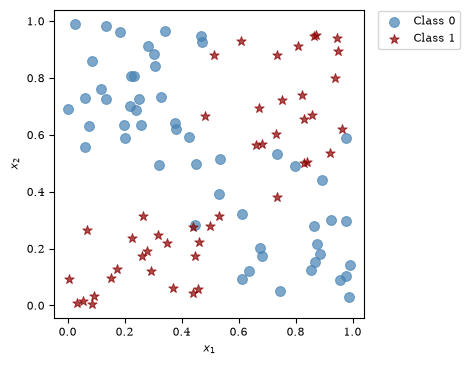

In [6]:
from lecture4_plots import plot_classes

# Plot demo dataset for classification
_ = plot_classes(X, y)

***
### Training and test samples

With real data, we would usually reserve a test sample before fitting or tuning
our models. For classification, we can use a *stratified* split so that the
training and test samples have approximately the same proportions of each class.
We can do this with
[`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
by passing the class labels through `stratify=y`.

The following cell demonstrates this split. We use names ending in `_demo`
because these subsets are only an illustration:

In [7]:
from sklearn.model_selection import train_test_split

# Fraction of the dataset to be used for testing
test_size = 0.3

# Demonstrate a stratified split for a dataset with a fixed sample size
X_train_demo, X_test_demo, y_train_demo, y_test_demo = train_test_split(
    X, y, stratify=y, test_size=test_size, random_state=1234
)

The class proportions in these two demo subsets are close, although their small
sizes mean that the proportions need not match exactly:

In [8]:
print('Distribution of classes in demo training sample:')
print(pd.Series(y_train_demo).value_counts() / len(y_train_demo))

print('\nDistribution of classes in demo test sample:')
print(pd.Series(y_test_demo).value_counts() / len(y_test_demo))

Distribution of classes in demo training sample:
0    0.542857
1    0.457143
Name: count, dtype: float64

Distribution of classes in demo test sample:
0    0.533333
1    0.466667
Name: count, dtype: float64


For our synthetic example, we can generate independent observations whenever we
need them. We therefore use all 100 observations for training. After fitting
and tuning the logistic regression, decision tree, and random forest models, we
will generate a fresh test sample of 10,000 observations from the same
process to compare their predictions.

Until that final comparison, we use training observations for the plots and
metric examples. Training scores describe the fit to observations already seen
by the model; they do not measure performance on new observations.

In [9]:
# Use the complete synthetic sample for training
X_train = X
y_train = y

***
## Logistic regression

Logistic regression is a well-established approach to performing classification tasks in
econometrics. In the binary setting, we model the probability of the outcome being 1 as
$$
p(\mathbf{x}_i) \equiv 
\text{Prob}\bigl(y_i = 1 ~|~\mathbf{x}_i\bigr) 
    = \frac{1}{1 + \exp\bigl(-\left(\mu + \mathbf{x}_i'\bm\beta\right)\bigr)}
$$
where the function on the right $\sigma(z) = \frac{1}{1+e^{-z}}$ is called the
[sigmoid function](https://en.wikipedia.org/wiki/Sigmoid_function) 
in machine learning or the
[logistic](https://en.wikipedia.org/wiki/Logistic_distribution)
cumulative distribution function (CDF) in statistics and econometrics. Note that this
function maps any (positive or negative) real value $z$ into a value in the interval
$(0, 1)$, and hence is well suited to modeling the probability that $y_i = 1$.

We can easily verify this by plotting the logistic CDF from `scipy.stats`, using
the helper function `plot_sigmoid()` from `lecture4_plots.py`:

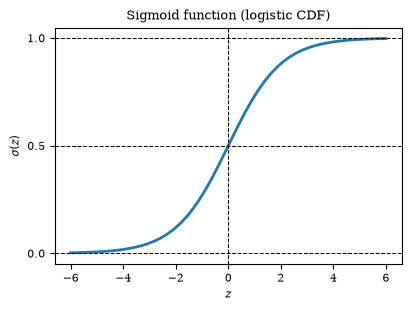

In [10]:
from lecture4_plots import plot_sigmoid

_ = plot_sigmoid()

As you can see, the value of $\sigma(z)$ approaches 0 as $z$ becomes increasingly
negative, and it approaches 1 for large values of $z$.

In machine learning, logistic regression is categorized as a linear model (see the
scikit-learn user guide on
[linear models](https://scikit-learn.org/stable/modules/linear_model.html)) even though $\sigma(z)$ is clearly not linear.
This is because the index $z_i$ that enters the sigmoid function is assumed to be linear
in the features $\mathbf{x}_i$,
$$
z_i = \mu + \mathbf{x}_i'\bm\beta
$$
Consequently, one can show that the log odds are a linear function of features:
$$
\log\left( \frac{p(\mathbf{x}_i)}{1-p(\mathbf{x}_i)} \right) = \mu + \mathbf{x}_i'\bm\beta
$$

Before we can fit the model using logistic regression, we need to define an appropriate
loss function. This loss function is derived from the log-likelihood function of a
binary logit model, defined as
$$
\mathcal{L}(\mu,\bm\beta) =
    \sum_{i=1}^N \Bigl[
        y_i \log\bigl(p(\mathbf{x}_i)\bigr)
        + (1-y_i) \log\bigl(1-p(\mathbf{x}_i)\bigr)
    \Bigr]
$$
The details underlying the derivation of this log-likelihood function are beyond the
scope of this course. For our purposes, it's sufficient to know that in maximum
likelihood estimation (MLE), the parameters $\mu$ and $\bm\beta$ are chosen so that the
log-likelihood $\mathcal{L}$ of observing a given sample of $(y_i,\mathbf{x}_i)$ is
*maximized*.

In machine learning, we typically minimize a loss function instead of maximizing a likelihood function. 
To derive the loss function $L$ for the logistic regression, we simply take the *negative* log-likelihood function and find the parameters $(\mu, \bm\beta)$ which *minimize* the loss $L$:
$$
L(\mu, \bm\beta) = 
- \underbrace{\frac{1}{N} \mathcal{L}(\mu,\bm\beta)}_{\text{scaled log-likelihood}} 
+ \underbrace{\frac{r(\bm\beta)}{NC}}_{\text{regularization}}
$$
Moreover, we have already incorporated the scaled regularization term
$\frac{r(\bm\beta)}{NC}$, where $r(\bullet)$ is a function of $\bm\beta$,
which is used analogously to Ridge regression and Lasso to shrink the parameters
$\bm\beta$ and prevent overfitting. We divide both the negative log-likelihood
and the penalty by $N$ to match scikit-learn's convention for $C$.
The fitted logistic regression parameters are thus
$$
\left(\widehat{\mu}, \widehat{\bm\beta}\right) = 
\argmin_{\mu,\bm\beta} L(\mu,\bm\beta)
$$

***
### Fitting a simple model

We first fit logistic regression to the synthetic training sample without imposing any
regularization, thus setting $C = \infty$. We'll cross-validate the regularization
strength later.

#### Specifying the regularization strength

We proceed to fit the model using the
[`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) 
estimator from `scikit-learn`. `LogisticRegression` implements four different types of regularization
which correspond to different functional forms for $r(\bullet)$ in the penalty term: 

1.  the *L1 penalty* we encountered with Lasso; 
2.  the *L2 penalty* from the Ridge regression; 
3.  the convex combination of these used for the *elastic net*; or 
4.  *no penalty* (this then corresponds to the classical binary logit used in econometrics to model discrete choice).

The following table lists the available regularization terms and the corresponding
arguments for `LogisticRegression`. The argument `C` is the *inverse* penalty
strength: *higher* values of `C` *decrease* regularization.

| Penalty type | $r(\bm\beta)$ | `l1_ratio` | `C` |
|--------------|---------------|------------|-------|
| L1 | $r(\bm\beta) = \lVert\bm\beta\rVert_1 = \sum_{k=1}^K \|\beta_k\|$ | 1 | desired inverse penalty |
| L2 | $r(\bm\beta) = \frac{1}{2}\lVert\bm\beta\rVert_2^2 = \frac{1}{2}\sum_{k=1}^K \beta_k^2$ | 0 | desired inverse penalty |
| L1 and L2 | $r(\bm\beta) = \rho\lVert\bm\beta\rVert_1 + \frac{1-\rho}{2}\lVert\bm\beta\rVert_2^2$ | $0 < \rho < 1$ | desired inverse penalty |
| None | 0 | 0 | `np.inf` |

The default solver, `'lbfgs'`, supports L2 regularization and unpenalized models. For L1
or elastic net, we can use `solver='saga'`.

#### Fitting the logistic regression model

We first experiment with the simplest possible linear model of two explanatory variables where
$$
z_i = \mu + \beta_1 x_{1i} + \beta_2 x_{2i}
$$
so that the probability of observing class 1 is
$$
p(\mathbf{x}_i) \equiv 
\text{Prob}\bigl(y_i = 1 ~|~\mathbf{x}_i\bigr) 
    = \frac{1}{1 + \exp\bigl(-\left(\ \mu + \beta_1 x_{1i} + \beta_2 x_{2i}\right)\bigr)}
$$
For now, we omit regularization by specifying `C=np.inf`.

In [11]:
from sklearn.linear_model import LogisticRegression

# Create logistic regression model without regularization penalty
lr = LogisticRegression(C=np.inf, fit_intercept=True, max_iter=1000)

Note that we also skipped input scaling here since we have only two features without
polynomial interactions, and these only take values on the interval $[0, 1]$. Hence
there is no need for scaling to address any potential numerical stability issues.

The following code fits the logistic regression model to the training sample:

In [12]:
lr.fit(X_train, y_train)

# Retain the fitted linear model
lr_linear = lr

With `C=np.inf`, we estimate the coefficients using only the logistic loss.
We introduce a finite value of `C` when we add regularization below.

***
### Assessing model accuracy

We first plot the decision boundaries implied by the fitted model. To this end, we
use the helper function `plot_decision_boundary()` implemented in
`lecture4_plots.py`. The function takes as argument an existing Matplotlib
`Axes` object and adds the decision boundaries to an existing figure.

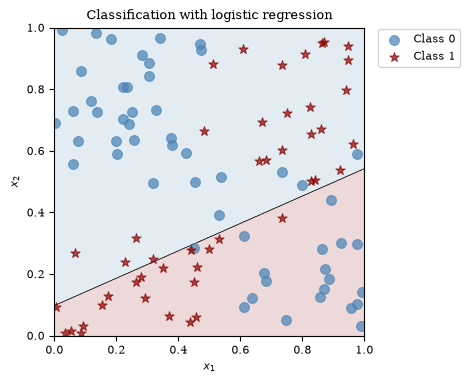

In [13]:
from lecture4_plots import plot_decision_boundary

# Create x-values to evaluate decisions (used for either dimension)
xvalues = np.linspace(0, 1, 1000)

ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, lr)
_ = ax.set_title('Classification with logistic regression')

The simple linear model misclassifies many training observations. For any
combination of $(x_{1i}, x_{2i})$ in the blue area, it predicts $y_i=0$; in the
red area, it predicts $y_i=1$.

We can compute accuracy, the share of correctly predicted class labels, using
the estimator's
[`score()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.score)
method or the
[`accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html)
function. These return the same result. We use training predictions here to
illustrate the calculation and reserve the independent test comparison for
later.

In [14]:
# Predict class labels for the training observations
y_train_pred = lr.predict(X_train)

In [15]:
from sklearn.metrics import accuracy_score

# Compute training accuracy
acc_train = accuracy_score(y_train, y_train_pred)
print(f'Training accuracy:  {acc_train:.3f}')

Training accuracy:  0.550


Alternatively, we can use the
[`score()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.score)
method directly to compute the same training accuracy:

In [16]:
acc_train = lr.score(X_train, y_train)
print(f'Training accuracy:  {acc_train:.3f}')

Training accuracy:  0.550


There are other metrics to assess how well the model predicts class labels. These usually combine the elements of the following confusion matrix in some way. 

First, consider the confusion matrix for a generic classification problem (with labels `P` and `N` for `Positive` and `Negative`), plotted below:

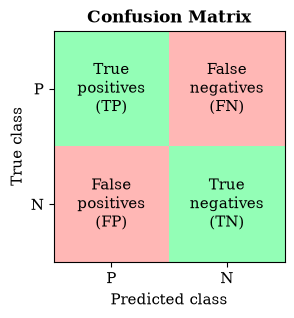

In [17]:
from lecture4_plots import plot_generic_confusion_matrix

plot_generic_confusion_matrix()

As you see, a classifier would ideally make predictions that fall in the green diagonal
cells. Using the labels of this matrix, the accuracy score we have computed above is
given by
$$
ACC = \frac{TP + TN}{FP + FN + TP + TN}
$$
However, we might be interested in different measures, for example *precision*, defined
as
$$
PRE = \frac{TP}{TP + FP}
$$
which is the share of true positives among all observations that are predicted as
positive by the model, or *recall*, defined as
$$
REC = \frac{TP}{FN + TP}
$$
which is the share of true positives among all observations that are truly positive in
the data.

Another commonly used scoring metric is the so-called *F1 score*, computed as
$$
F1 = 2 \frac{PRE \cdot REC}{PRE + REC}
$$
Which metric we use depends on the application.

Scikit-learn implements many commonly used scoring metrics in the module
[`sklearn.metrics`](https://scikit-learn.org/stable/api/sklearn.metrics.html).
We define `tabulate_training_metrics()` to compute and print these four metrics
for our training predictions:

In [18]:
from sklearn.metrics import f1_score, precision_score, recall_score


def tabulate_training_metrics(y_train, y_train_pred):
    """
    Print accuracy, precision, recall, and F1 score for training predictions.

    Parameters
    ----------
    y_train : array
        Observed class labels in the training sample.
    y_train_pred : array
        Predicted class labels for the training observations.
    """
    acc_train = accuracy_score(y_train, y_train_pred)
    pre = precision_score(y_train, y_train_pred)
    rec = recall_score(y_train, y_train_pred)
    f1 = f1_score(y_train, y_train_pred)

    print(f'Training accuracy:  {acc_train:.3f}')
    print(f'Training precision: {pre:.3f}')
    print(f'Training recall:    {rec:.3f}')
    print(f'Training F1 score:  {f1:.3f}')

In [19]:
tabulate_training_metrics(y_train, y_train_pred)

Training accuracy:  0.550
Training precision: 0.513
Training recall:    0.435
Training F1 score:  0.471


These metrics describe different aspects of the model's fit to the training
observations. We will assess performance on new observations after fitting all
main classifiers.

We can plot the confusion matrix using
[`ConfusionMatrixDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_predictions).
This plot can be created from predicted values or directly from an estimator. Here,
class 1 is positive, and scikit-learn orders the labels as 0, then 1, so true positives
appear in the lower-right cell. Below, we use the training predictions:

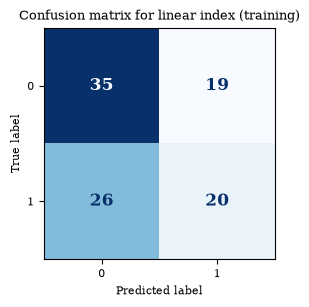

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

# Plot confusion matrix for the training predictions
_ = ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    colorbar=False,
    cmap='Blues',
    text_kw={'fontsize': 12, 'fontweight': 'bold'},
).ax_.set_title('Confusion matrix for linear index (training)')

The confusion matrix shows that there is a sizable number of misclassified observations
(the off-diagonal elements).

#### Class imbalance

In real applications, one class may be much rarer than the other. Suppose only
100 of 10,000 observations are positive, for example fraudulent transactions.
A classifier that always predicts the negative class achieves *99% accuracy*,
but detects none of the positive cases: its recall is *zero*. We should
therefore compare accuracy with the simple baseline of always predicting the
most common class.

When missing positive cases is costly, we pay particular attention to recall.
When false alarms are costly, precision also matters. 
F1 summarizes their tradeoff in a single number, but the
appropriate metric still depends on the costs of different mistakes.

We can also use
[`balanced_accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.balanced_accuracy_score.html),
which averages recall computed separately for each class. In our example, the
classifier that always predicts the negative class has balanced accuracy of
50%, since it identifies all negative cases and none of the positive cases.

***
### Digression: linear decision boundary

You might wonder why the decision boundary plotted earlier is a straight line even though the sigmoid function is clearly nonlinear. This arises because `LogisticRegression` assigns predictions based on the most likely class as determined by the predicted probabilities of belonging to each class for each observation. We can predict these underlying probabilities using the 
[`predict_proba()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.predict_proba) 
method, for example for the first five training observations:

In [21]:
# Predict probabilities for the first five training observations
lr.predict_proba(X_train)[:5]

array([[0.44213578, 0.55786422],
       [0.58697448, 0.41302552],
       [0.4489442 , 0.5510558 ],
       [0.49038364, 0.50961636],
       [0.56350387, 0.43649613]])

Based on these predicted probabilities, `LogisticRegression` assigns the predicted class
as the most likely outcome. With only two categories, $\widehat{y}_i = 1$ is therefore
predicted whenever the value in the second column is larger than 0.5. Using the fitted
coefficients in the sigmoid function, we have

$$
\begin{aligned}
\widehat{y}_i = 1
& \Longleftrightarrow
\sigma(\widehat{\mu} + \widehat{\beta}_1 x_{1i} + \widehat{\beta}_2 x_{2i})
    > 0.5 \\
& \Longleftrightarrow
\frac{1}{1+\exp\left(
    -\widehat{\mu} - \widehat{\beta}_1 x_{1i} - \widehat{\beta}_2 x_{2i}
\right)} > 0.5 \\
& \Longleftrightarrow
\exp\left(
    -\widehat{\mu} - \widehat{\beta}_1 x_{1i} - \widehat{\beta}_2 x_{2i}
\right) < 1 \\
& \Longleftrightarrow
\widehat{\mu} + \widehat{\beta}_1 x_{1i} + \widehat{\beta}_2 x_{2i} > 0 \\
& \Longleftrightarrow
x_{2i} < - \frac{\widehat{\mu}}{\widehat{\beta}_2}
    - \frac{\widehat{\beta}_1}{\widehat{\beta}_2} x_{1i}
\end{aligned}
$$

The last step above follows because $\widehat{\beta}_2 < 0$ in this example, as you can
verify by checking the attribute `lr.coef_`. The takeaway from these derivations is that
any combination of features $x_{1i}, x_{2i}$ is mapped to $\widehat{y}_i = 1$ if
$x_{2i}$ lies underneath the line defined by $-\frac{\widehat{\mu}}{\widehat{\beta}_2} -
\frac{\widehat{\beta}_1}{\widehat{\beta}_2} x_{1i}$, and therefore the decision boundary
is a *straight line*.

***
### Fitting a model with polynomials

We now extend the simple model and approximate the nonlinear relationship between $y_i$
and $\mathbf{x}_i$ using polynomials in $x_{1i}, x_{2i}$ where we allow for interaction
terms up to some upper bound:
$$
z_i = \mu + \beta_1 x_{1i} + \beta_2 x_{2i} + \beta_3 x_{1i} x_{2i} + \beta_4 x_{1i}^2 + \beta_5 x_{2i}^2 + \dots
$$

In [22]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

# Maximum polynomial degree
degree = 5

# Create logistic regression model without regularization penalty
lr = LogisticRegression(fit_intercept=True, C=np.inf, max_iter=1_000)

# Create pipeline with polynomial features and logistic regression
pipe_lr = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=degree, include_bias=False),
    StandardScaler(),
    lr,
)

At this point we don't strictly need to scale the polynomial features using the `StandardScaler`, but this will be necessary below when we introduce a regularization term.

We can now fit the model on the training data:

In [23]:
pipe_lr.fit(X_train, y_train)

# Retain the unpenalized polynomial pipeline
lr_pipe_unpenalized = pipe_lr

Using the functions defined above, we can plot the decision boundaries of this more complex model:

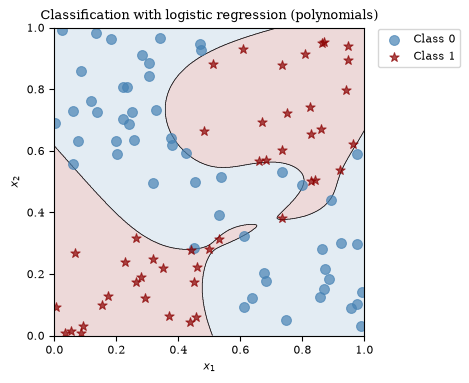

In [24]:
# Create x-values used to evaluate decisions
xvalues = np.linspace(0, 1, 1000)
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, pipe_lr)
_ = ax.set_title('Classification with logistic regression (polynomials)')

The polynomial features allow a more flexible decision boundary. We can compute
the same metrics to see how well this model fits the training observations:

In [25]:
# Predict class labels for the training observations
y_train_pred = pipe_lr.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred)

Training accuracy:  1.000
Training precision: 1.000
Training recall:    1.000
Training F1 score:  1.000


The confusion matrix summarizes these training predictions. A good fit to the
training observations can still come with overfitting, so we will compare the
models on independent test observations later.

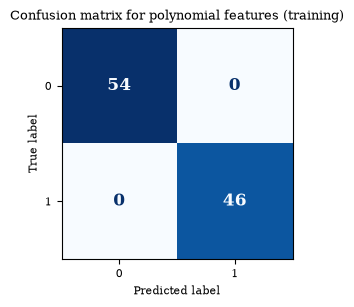

In [26]:
# Plot confusion matrix for the training predictions
_ = ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    colorbar=False,
    cmap='Blues',
    text_kw={'fontsize': 12, 'fontweight': 'bold'},
).ax_.set_title('Confusion matrix for polynomial features (training)')

As you see from the above metrics and the confusion matrix, the model with a degree 5
polynomial predicts *every single* observation in the training sample correctly.
However, the diagnostic plot above suggests overfitting, as the decision boundaries are
highly irregular and follow the training observations too closely.

***
### Cross-validating the penalty term

So far, we haven't introduced a regularization term when fitting the logistic
regression. Analogous to Ridge regression and Lasso, regularization can help
prevent overfitting.
Since we don't know the best regularization parameter $C$, we use
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
around the complete pipeline.

We first define a cross-validation splitter and scoring metric that we will use for all models in this lecture:

In [27]:
from sklearn.model_selection import StratifiedKFold

# Reproducible shuffled folds that preserve the class proportions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1234)

# Define the scoring metric for model evaluation
scoring = 'accuracy'

We define five folds with
[`StratifiedKFold()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
to keep the class proportions approximately equal across folds. We set
`shuffle=True` and `random_state=1234` to shuffle observations within each class
and make the splits reproducible. Shuffling is not needed for this example
because our training observations were already drawn independently in random
order. We include it to make the split strategy explicit.

Stratified splitting preserves class proportions across subsets; it does not
remove the imbalance or make accuracy informative about rare positive cases.
With severe imbalance, we also need enough minority-class observations for the
chosen number of CV folds.

We set `scoring='accuracy'` because our classes are approximately balanced and
we count mistakes in both classes equally.

If we choose balanced accuracy or F1 for an application, we can pass
`scoring='balanced_accuracy'` or `scoring='f1'` to `GridSearchCV`. We choose the
scoring rule before tuning and report the relevant metrics on independent test
observations.

We construct the estimation pipeline as usual: The first scaler standardizes the
original features, and the second standardizes the polynomial features. In each fold, we
fit each `StandardScaler` using only the training observations and apply those fitted
means and standard deviations to the validation observations. Fitting either scaler on
the entire training sample before cross-validation would let the validation observations
influence the transformation used for fitting. This is *data leakage*, even though the
scalers do not use the labels. Our synthetic sample is no exception: the polynomial
columns' sample means and standard deviations still depend on the observations. The
polynomial expansion itself uses fixed powers and learns no means or scales, but we keep
all preprocessing inside the pipeline so the complete procedure is cross-validated.

For this example, we use the L2 penalty, selected with `l1_ratio=0.0`. 
The complete pipeline is defined as follows:

In [28]:
# Pipeline with polynomial features, scaling, and L2 logistic regression
pipe_lr = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    LogisticRegression(l1_ratio=0.0, max_iter=1_000),
)

We try 100 values of $C$, spaced evenly on a log scale between $10^{-2}$ and $10^2$. The
pipeline parameter `logisticregression__C` uses the step name and parameter name
separated by a double underscore. Additionally, we cross-validate the polynomial degree,
which is specified by the pipeline parameter `polynomialfeatures__degree`. We try
degrees 1 through 5.

In [29]:
from sklearn.model_selection import GridSearchCV

# Candidate inverse penalty strengths, spaced uniformly in logs on [1e-2, 1e2]
c_values = np.logspace(-2, 2, 100)

# Candidate polynomial degrees
degrees = [1, 2, 3, 4, 5]

# Define the parameter grid for GridSearchCV
param_grid = {'polynomialfeatures__degree': degrees, 'logisticregression__C': c_values}

# Define the GridSearchCV object for hyperparameter tuning
lr_cv = GridSearchCV(
    estimator=pipe_lr,
    param_grid=param_grid,
    scoring=scoring,
    cv=cv,
    refit=True,
    n_jobs=4,
)

We run the search on the original training features. `GridSearchCV` fits both scalers
and the classifier separately within each fold:

In [30]:
# Run cross-validation on the original, unscaled features
lr_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': array([1.0000...00000000e+02]), 'polynomialfeatures__degree': [1, 2, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",Tr

Once cross-validation is complete, we can retrieve the selected $C$ and polynomial
degree from `best_params_` and the corresponding mean validation accuracy from
`best_score_`:

In [31]:
print(f'Best C:                   {lr_cv.best_params_["logisticregression__C"]:.4f}')
print(f'Best polynomial degree:   {lr_cv.best_params_["polynomialfeatures__degree"]}')
print(f'Best validation accuracy: {lr_cv.best_score_:.3f}')

Best C:                   0.6579
Best polynomial degree:   4
Best validation accuracy: 0.910


Note that unlike the penalty parameters used for Ridge and Lasso, $C$ in this case is the *inverse* penalty strength, i.e., larger values of $C$ introduce a *smaller* penalty.

With `refit=True`, `GridSearchCV` refits the selected pipeline on the entire training
sample and stores it in `best_estimator_`. We can use that pipeline directly for
predictions and plots; it already contains the fitted polynomial expansion, scalers, and
classifier.

In [32]:
# Recover the pipeline refitted with the selected C and degree
lr_pipe_opt = lr_cv.best_estimator_

We reuse the plotting code from above to plot the decision boundaries for the optimal model:

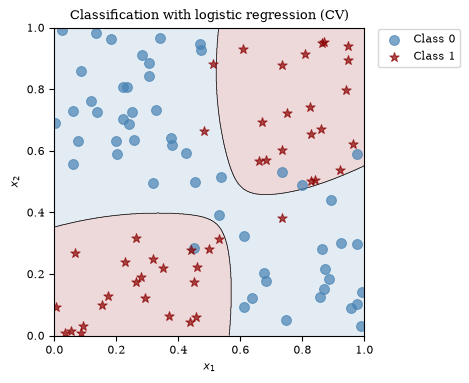

In [33]:
# Create x-values used to evaluate decisions
xvalues = np.linspace(0, 1, 1000)
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, lr_pipe_opt)
_ = ax.set_title('Classification with logistic regression (CV)')

We can compute the selected pipeline's training accuracy, precision, recall,
and F1 score using the same functions as before:

In [34]:
# Compute training metrics for the cross-validated model
y_train_pred = lr_pipe_opt.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred)

Training accuracy:  0.930
Training precision: 0.915
Training recall:    0.935
Training F1 score:  0.925


All tuning uses only the training sample. We leave the independent test
comparison until after the random forest section, when all main models have
been fitted.

### Dedicated cross-validation with `LogisticRegressionCV`

The dedicated
[`LogisticRegressionCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html)
class can reuse coefficient estimates along the regularization path, making it
faster than fitting each candidate independently. It is useful when no
preprocessing needs to be learned within the folds.

For this illustration, we construct polynomial features directly from the
original inputs, without fitting a scaler. We keep degree 4, which the preceding
grid search selected. `LogisticRegressionCV` tunes the regularization strength
for a fixed feature matrix, so it does not also cross-validate the polynomial
degree.

The earlier grid search included scaling, which changes how regularization acts
on the polynomial coefficients. Degree 4 is therefore not guaranteed to be
optimal for this specification, and the selected $C$ values are not directly
comparable.

We specify accuracy scoring explicitly.

With `use_legacy_attributes=False`, `C_` is a scalar, which we can format directly.

In [35]:
from sklearn.linear_model import LogisticRegressionCV

# Candidate inverse penalty strengths, spaced uniformly in logs on [1e-2, 1e2]
c_values_dedicated = np.logspace(-2, 2, 100)

# Polynomial features with degree 4 selected by the preceding grid search
poly_fixed = PolynomialFeatures(degree=4, include_bias=False)
X_train_fixed = poly_fixed.fit_transform(X_train)

# Dedicated cross-validation on these fixed polynomial features
lr_cv_dedicated = LogisticRegressionCV(
    Cs=c_values_dedicated,
    cv=cv,
    scoring=scoring,
    l1_ratios=(0.0,),
    max_iter=1_000,
    n_jobs=4,
    use_legacy_attributes=False,
).fit(X_train_fixed, y_train)

print(f'LogisticRegressionCV selected C: {lr_cv_dedicated.C_:.4f}')

LogisticRegressionCV selected C: 1.2619


***
### Validation curves

A validation curve plots a model's validation score against a hyperparameter, here $C$.
We use
[`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html)
to fit the complete pipeline within each fold and compute training and validation
accuracy for a range of values of $C$. We define a separate pipeline with the polynomial
degree fixed at 4, as selected by the preceding grid search, since we want to focus on
the effect of $C$ on the model's performance.

The argument `param_name` identifies the parameter to vary. For our pipeline,
`logisticregression__C` combines the step name and parameter name with a double
underscore. The argument `param_range` supplies the candidate values.
We use the same stratified folds and accuracy scoring rule as in our grid search:

In [36]:
from sklearn.model_selection import validation_curve

# Pipeline for the validation curve with polynomial degree fixed at 4
pipe_lr_validation = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=4, include_bias=False),
    StandardScaler(),
    LogisticRegression(l1_ratio=0.0, max_iter=1_000),
)

# Define range of values for C, spaced uniformly in logs
param_range = np.logspace(-4, 4, 100)

# Parameter name
param_name = 'logisticregression__C'

# Compute validation curve
train_scores, test_scores = validation_curve(
    estimator=pipe_lr_validation,  # Estimator pipeline
    X=X_train,  # Training data
    y=y_train,  # Training labels
    param_name=param_name,  # Parameter name for C in pipeline
    param_range=param_range,  # Range of C values to evaluate
    cv=cv,  # Same stratified folds as in the grid search
    scoring=scoring,  # Same scoring rule as in the grid search
    n_jobs=4,  # Number of parallel jobs
)

The module `lecture4_plots` implements the function `plot_accuracy_validation_curve()`
which we can use to plot the validation curve for a given range of parameter values. The
lines show mean accuracy across folds. The shaded bands extend one standard deviation
above and below the means. We pass the metric name through `score` so that the axis and
legend labels match the scoring rule:

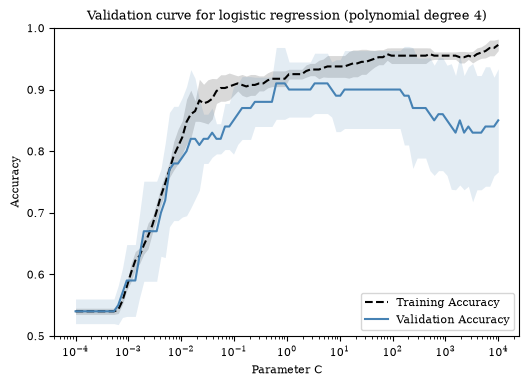

In [37]:
from lecture4_plots import plot_accuracy_validation_curve

plot_accuracy_validation_curve(
    param_range,
    train_scores,
    test_scores,
    score='Accuracy',
    title='Validation curve for logistic regression (polynomial degree 4)',
)

As the plot shows, small values of $C$ (large penalty strengths) can lead to
underfitting, with low accuracy on both the training and validation folds.
At large values of $C$, higher training accuracy can come with lower validation
accuracy, suggesting overfitting.

***
## Decision trees

Decision trees are nonlinear classifiers that are constructed by splitting the sample in
two at each branch according to some criterion (e.g., if feature 1 is larger than a
value $a$). Fitting a decision tree is the process of growing a tree and finding the
criteria that split the sample to achieve the largest reduction in impurity. In
principle, a tree could be grown until each leaf node is pure, i.e., it contains only
observations from a single class. In practice, this can lead to very deep trees which
tend to overfit the data, so it's advisable to limit the tree's growth by specifying a
maximum depth.

It should be stressed that decision trees are fully nonlinear models, so there is usually no need to expand the feature space using polynomial interactions. 
Moreover, decision trees are not sensitive to scaling, so we can skip the entire data processing pipeline we used for other classifiers.

Decision trees are implemented in the
[`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)
class in scikit-learn. We use the same 100 training observations as for logistic
regression, so the final test comparison will assess models fitted on the same sample.
We grow the tree by fitting it to the training data. For the reasons explained above, we
limit the maximum tree depth to 3 by specifying the argument `max_depth=3`. We use
`criterion='gini'` to favor splits that produce groups with less mixed class labels, and
`random_state=1234` to make the result reproducible when several splits are equally
good.

In [38]:
from sklearn.tree import DecisionTreeClassifier

# Create decision tree classifier
tree = DecisionTreeClassifier(criterion='gini', max_depth=3, random_state=1234)

# Grow tree on training data (no transformation needed)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1234
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples a

We now plot the decision boundaries of the fitted decision tree. As you can see, the boundaries are all parallel to the axes, which is by construction.

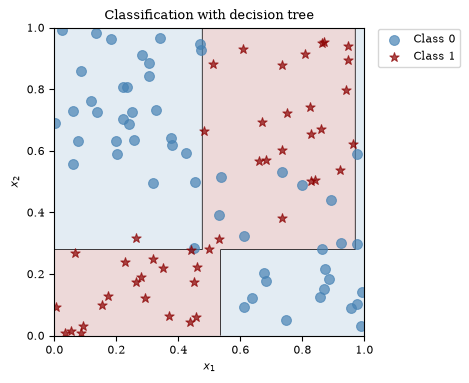

In [39]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, tree)
_ = ax.set_title('Classification with decision tree')

We can compute the tree's training accuracy, precision, recall, and F1 score.
As before, these describe the fit to observations already used to grow the tree:

In [40]:
y_train_pred_tree = tree.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_tree)

Training accuracy:  0.910
Training precision: 0.849
Training recall:    0.978
Training F1 score:  0.909


Scikit-learn offers a convenience function that visualizes the fitted tree. At each
non-leaf node, the first line states the splitting criterion, the second reports the
number of observations at that node, and the third gives the class counts in the order
`[class 0, class 1]`. Leaf nodes show only the sample and class counts.

We can follow an observation down the tree by comparing its feature values with
the displayed thresholds. A leaf containing observations from only one class is
called *pure*.

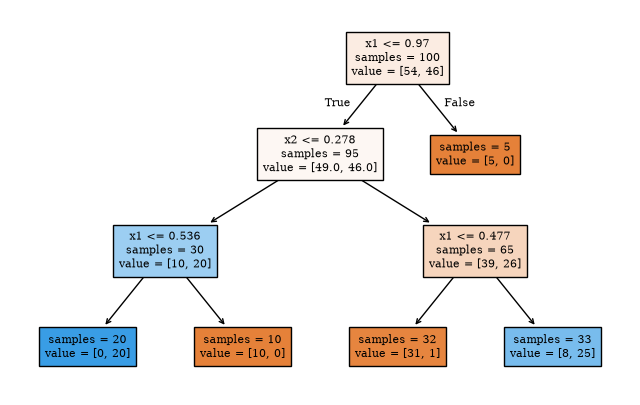

In [41]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Visualize nodes of fitted decision tree
fig, ax = plt.subplots(figsize=(8, 5))
_ = plot_tree(
    tree, filled=True, feature_names=['x1', 'x2'], fontsize=8, impurity=False, ax=ax
)

We fitted the tree above choosing a maximum tree depth ourselves. The tree depth is a
hyperparameter, so we should as usual use cross-validation to select its value. To do
this, we again use the
[`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
cross-validator to find the optimal tree depth for this sample. For now, we vary only
`max_depth`. The random forest section introduces additional hyperparameters. We reuse
the stratified folds and accuracy scoring rule from logistic regression.

In [42]:
# Create decision tree classifier used for CV
tree = DecisionTreeClassifier(criterion='gini', random_state=1234)

# Define range of values for max_depth
max_depth = np.arange(1, 11)

# Parameter grid for GridSearchCV
param_grid = {'max_depth': max_depth}

tree_cv = GridSearchCV(
    estimator=tree, param_grid=param_grid, scoring=scoring, cv=cv, refit=True, n_jobs=4
).fit(X_train, y_train)

print(f'Best validation accuracy: {tree_cv.best_score_:.3f}')
print(f'Best max depth:           {tree_cv.best_params_["max_depth"]}')

Best validation accuracy: 0.800
Best max depth:           4


The output reports the depth selected by cross-validation. We can plot the
decision boundary of the tree refitted on all 100 training observations:

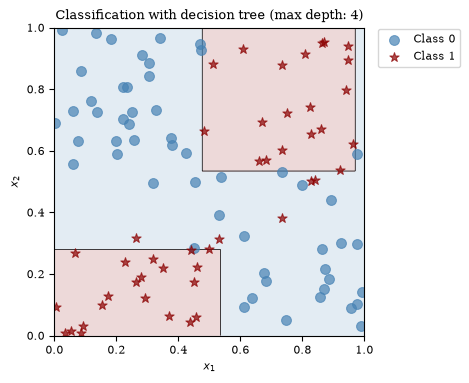

In [43]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, tree_cv)
_ = ax.set_title(
    f'Classification with decision tree (max depth: {tree_cv.best_params_["max_depth"]})'
)

The training metrics below show how closely the selected tree fits our sample.
We will compare its predictions on new observations with those of the other
classifiers in the final test comparison.

In [44]:
# Predicting using the best decision tree model
y_train_pred_tree = tree_cv.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_tree)

Training accuracy:  0.940
Training precision: 1.000
Training recall:    0.870
Training F1 score:  0.930


***
## Random forest

A random forest classifier is an *ensemble method*, which means that we combine
predictions from multiple models into a single prediction. Here, we fit multiple
decision trees on bootstrap samples of the data, drawn with replacement, and average
their predicted class probabilities. This model averaging is intended to lead to less
overfitting and higher predictive accuracy. The random forest classifier is implemented
in
[`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html)
in scikit-learn.

Just like decision trees, a random forest can capture nonlinear relationships
without polynomial features and does not require feature standardization. We can
therefore fit it directly on the original features.

The following hyperparameters control how the algorithm grows and combines the trees:

- `n_estimators`: the number of trees. Averaging more trees makes predictions
  more stable; beyond some point, additional trees change predictions little.
- `max_features`: the number of features randomly selected as candidates at each
  split. An integer specifies a count, so `1` considers one feature. A float
  specifies a fraction of all features, so `1.0` considers all features and `0.5`
  considers half (rounded down, with a minimum of one). The default `'sqrt'`
  uses the square root of the total number of features, rounded down; with our
  two features, it considers one.
- `max_depth`: the maximum tree depth. Smaller values limit complexity;
  `None` leaves the depth unrestricted.
- `min_samples_leaf`: the minimum number of observations in each leaf.
  Larger values prevent the tree from creating very small terminal groups.
- `min_samples_split`: the minimum number of observations a node needs before
  we consider splitting it. This does not set a minimum size for each child.

`max_depth`, `min_samples_leaf`, and `min_samples_split` also apply to a single
decision tree.
For example, `min_samples_split=10` can allow a node with ten observations to
split into groups of one and nine. Setting `min_samples_leaf=5` rules out that
split because both resulting groups must contain at least five observations.

In [45]:
from sklearn.ensemble import RandomForestClassifier

# Create random forest classifier, fit on training data
forest = RandomForestClassifier(
    n_estimators=100,  # Number of trees in the forest
    max_depth=3,  # Maximum depth of each tree
    random_state=1234,  # Random seed for bootstrapping and feature selection
    n_jobs=4,  # Number of parallel jobs to run for both fit and predict
)

# Fit the random forest model on the training data
forest.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",4
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",1234
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total n

Compared to a single decision tree, the random forest leads to more granular decision boundaries which are due to the averaging of many decision trees.

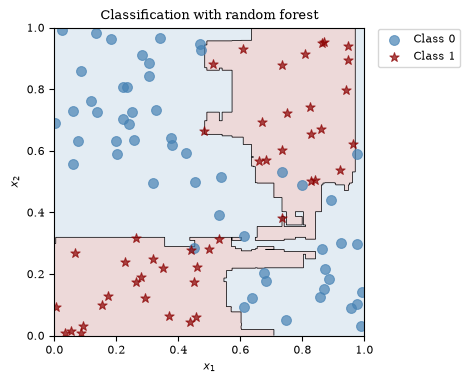

In [46]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, forest)
_ = ax.set_title('Classification with random forest')

We can compute the random forest's training accuracy, precision, recall, and
F1 score in the same way:

In [47]:
y_train_pred_forest = forest.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_forest)

Training accuracy:  0.960
Training precision: 0.938
Training recall:    0.978
Training F1 score:  0.957


We use
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
to select the maximum tree depth and number of trees. We try depths from 5 to 15 and
tree counts from 100 to 190 in steps of 10, giving $11 \times 10 = 110$ combinations.
Each candidate uses the same five stratified folds and accuracy scoring rule as before.

We leave the other forest parameters at their defaults in this example. The
hyperparameters listed above give us further ways to control the model in
other applications.

Note that we set `n_jobs=1` when constructing the random forest. This is because the random forest itself can be parallelized, but we also parallelize the cross-validation. Setting `n_jobs=-1` for both would oversubscribe the CPU and slow down the computation.

In [48]:
# Fit each forest with one job; parallelize the grid search below
forest_tune = RandomForestClassifier(random_state=1234, n_jobs=1)

# Candidate ranges for depth and number of trees
max_depth_grid = np.arange(5, 16)
n_estimators_grid = np.arange(100, 200, 10)
param_grid = {'max_depth': max_depth_grid, 'n_estimators': n_estimators_grid}

# Create GridSearchCV object for hyperparameter tuning of the random forest
forest_cv = GridSearchCV(
    estimator=forest_tune,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit=True,
    n_jobs=4,
)

# Run cross-validation on the original, unscaled features
forest_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...om_state=1234)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 5, 6..., 13, 14, 15]), 'n_estimators': array([100, 1...70, 180, 190])}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ver

In [49]:
print(f'Best validation accuracy: {forest_cv.best_score_:.3f}')
for param, value in forest_cv.best_params_.items():
    print(f'Best {param}: {value}')

Best validation accuracy: 0.880
Best max_depth: 10
Best n_estimators: 180


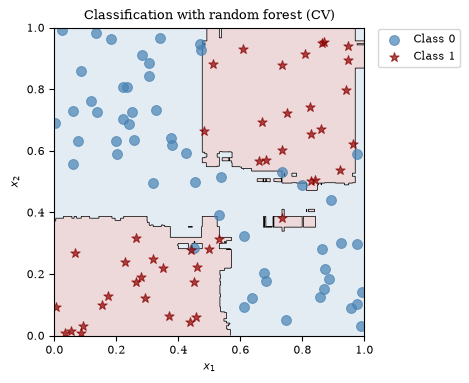

In [50]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, forest_cv)
_ = ax.set_title('Classification with random forest (CV)')

In [51]:
y_train_pred_forest_cv = forest_cv.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_forest_cv)

Training accuracy:  1.000
Training precision: 1.000
Training recall:    1.000
Training F1 score:  1.000


Here, all four training metrics equal 1 because the refitted forest classifies
every training observation correctly. Deep trees can isolate individual
observations, including noisy labels, and averaging their predictions can
preserve this fit.

In cross-validation, each forest predicts observations excluded from its training
fold, which explains why validation accuracy is lower. A perfect training fit
alone does not tell us whether the selected forest is too complex: we judge its
predictive performance using cross-validation and the independent test sample
below.

***
## Comparing predictions on new observations

We have now fitted and tuned the main classifiers using the same 100 training
observations. We generate 10,000 independent test observations from the same
process, with the same noise level, using a separate random generator. 
This larger test sample makes the comparison less sensitive to
chance variation in the test observations.

We use the fitted models directly to predict these new observations. The test
sample has played no part in fitting the models or selecting hyperparameters.

In [52]:
# Generate a large independent test sample after fitting all main models
rng_test = np.random.default_rng(seed=5678)
X_test, y_test = create_class_data(N=10_000, sigma=sigma_eps, rng=rng_test)

The tables below compare the classifiers selected by cross-validation using
accuracy, precision, recall, and F1 score for the training sample and the same
independent test sample. The training table also includes the mean validation
accuracy used to select hyperparameters in the `CV ACC` column. The CV scores
describe models trained within the folds; the training and test metrics evaluate
the final models refitted on all 100 training observations.

Here, the classes are approximately balanced and we count mistakes in both
classes equally, so we use accuracy to select hyperparameters. We report all
four metrics to show different aspects of model performance.
We use these tables to assess the fitted models without changing their
hyperparameters after seeing the test scores. A different training sample
could change the ranking, even with a large test sample.

In [53]:
# Compare models selected by cross-validation
models = {
    'Logistic, CV': lr_cv,
    'Decision tree, CV': tree_cv,
    'Random forest, CV': forest_cv,
}

# Report the same four metrics for the training and test samples
samples = {'Training': (X_train, y_train), 'Test': (X_test, y_test)}

for sample_name, (X_sample, y_sample) in samples.items():
    print(f'\n{sample_name} sample:')
    header = (
        f'{"Model":<25} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} '
        f'{"F1 score":>10}'
    )
    if sample_name == 'Training':
        header += f' {"CV ACC":>10}'
    print(header)
    for name, model in models.items():
        y_sample_pred = model.predict(X_sample)
        acc = accuracy_score(y_sample, y_sample_pred)
        pre = precision_score(y_sample, y_sample_pred)
        rec = recall_score(y_sample, y_sample_pred)
        f1 = f1_score(y_sample, y_sample_pred)

        row = f'{name:<25} {acc:10.3f} {pre:10.3f} {rec:10.3f} {f1:10.3f}'
        if sample_name == 'Training':
            cv_text = f'{model.best_score_:.3f}'
            row += f' {cv_text:>10}'
        print(row)


Training sample:
Model                       Accuracy  Precision     Recall   F1 score     CV ACC
Logistic, CV                   0.930      0.915      0.935      0.925      0.910
Decision tree, CV              0.940      1.000      0.870      0.930      0.800
Random forest, CV              1.000      1.000      1.000      1.000      0.880

Test sample:
Model                       Accuracy  Precision     Recall   F1 score
Logistic, CV                   0.842      0.874      0.796      0.833
Decision tree, CV              0.803      0.896      0.684      0.776
Random forest, CV              0.831      0.869      0.777      0.820


***
## Support vector machines (SVM)

We now turn to support vector machines, which classify observations by finding
a decision boundary with a wide *margin*, or buffer zone, between the classes.
We balance the width of this margin against a penalty for observations that lie
inside it or on the wrong side of the boundary. The observations that determine
the fitted boundary are called *support vectors*.
`scikit-learn` offers several implementations of SVMs that differ in the underlying algorithm and capabilities. We focus on the 
[`SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html)
(support vector classifier) class which supports both linear and nonlinear kernels.

Just like logistic regression, `SVC` uses the regularization parameter $C$. However,
SVMs offer additional flexibility in that they support various kernels. A kernel
measures similarity between observations in a way that lets the SVM work implicitly in a
different feature space. For example, we might have a classification problem like the
one we studied above, where the classes 0 and 1 clearly cannot be separated by a single
linear boundary. Instead of adding polynomial interactions, with SVMs we can specify a
nonlinear kernel in the hope that once the features have been represented in this
implicit feature space, the individual classes become much easier to separate.

### Linear kernel

We use exactly the same 100 training observations and 10,000 independent test
observations as for logistic regression, decision trees, and random forests.
We keep the same noise level and reuse the same stratified CV folds, so the
results are directly comparable.

We first fit the SVM specifications and examine their training predictions. After
tuning, we extend the earlier test comparison with the tuned RBF SVM. We start with the
simplest linear kernel which is selected using the `kernel='linear'` argument.

In [54]:
from sklearn.svm import SVC

# Create pipeline with linear SVM
pipe_svm = make_pipeline(StandardScaler(), SVC(kernel='linear', C=1.0))

# Fit the linear SVM model on the training data
pipe_svm.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Plotting the decision boundaries, we see that the linear kernel leads to a single linear decision boundary:

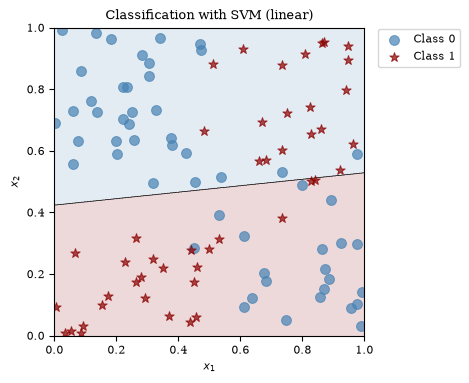

In [55]:
xvalues = np.linspace(0, 1, 1000)
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, pipe_svm)
_ = ax.set_title('Classification with SVM (linear)')

We can compute training accuracy, precision, recall, and F1 score for this linear
decision boundary. As with linear logistic regression, the model has limited
flexibility for our nonlinear classification problem:

In [56]:
y_train_pred_svm = pipe_svm.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_svm)

Training accuracy:  0.590
Training precision: 0.553
Training recall:    0.565
Training F1 score:  0.559


As with logistic regression, we can easily augment this model by adding polynomial interactions of features:

In [57]:
# Maximum polynomial degree
degree = 5

# Create pipeline with polynomial features and SVM
pipe_svm_poly = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=degree, include_bias=False),
    StandardScaler(),
    SVC(kernel='linear', C=1.0),
)

# Fit the polynomial SVM model on the training data
pipe_svm_poly.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


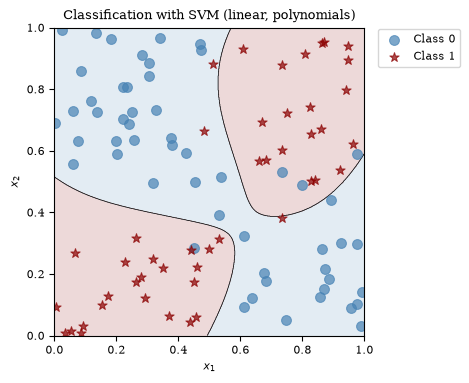

In [58]:
xvalues = np.linspace(0, 1, 1000)
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, pipe_svm_poly)
_ = ax.set_title('Classification with SVM (linear, polynomials)')

We compute training accuracy, precision, recall, and F1 score to assess the
fit of this more flexible model:

In [59]:
y_train_pred_svm = pipe_svm_poly.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_svm)

Training accuracy:  0.930
Training precision: 0.915
Training recall:    0.935
Training F1 score:  0.925


As expected, the polynomial features allow a more flexible decision boundary and lead to a better fit to the training observations.

### Gaussian kernel

However, it is not necessary to introduce polynomial features with SVM. Alternatively, we can operate with just the two original features, but choose a different kernel. By default, the kernel used by `SVC` is 
`kernel='rbf'` which stands for the *radial basis function*. This kernel is also called the Gaussian kernel.

We rerun the above code, omitting the polynomial features but instead selecting the Gaussian kernel:

In [60]:
# Create SVM with RBF kernel
pipe_svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=1.0, gamma='scale'))

# Fit the SVM model with RBF kernel on the training data
pipe_svm_rbf.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


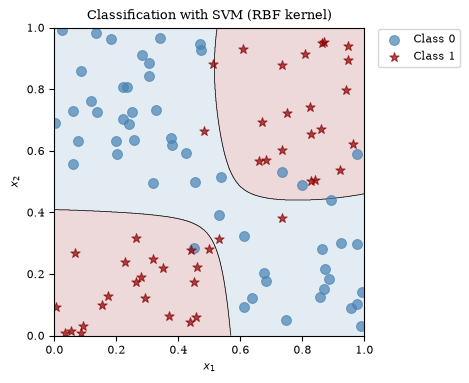

In [61]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, pipe_svm_rbf)
_ = ax.set_title('Classification with SVM (RBF kernel)')

We can compute the same four training metrics for the Gaussian kernel. After tuning, the
final test comparison will show how the selected RBF model performs on new observations:

In [62]:
y_train_pred_svm = pipe_svm_rbf.predict(X_train)

tabulate_training_metrics(y_train, y_train_pred_svm)

Training accuracy:  0.920
Training precision: 0.913
Training recall:    0.913
Training F1 score:  0.913


So far, we have used fixed SVM hyperparameters. For the RBF kernel, we now tune
both:

1. `C`, the inverse regularization penalty strength; and
2. `gamma`, which scales the squared Euclidean distance between feature vectors.

We use
[`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)
to evaluate all combinations of 50 values of `C` and 50 values of `gamma`.
As with the other classifiers, we use the same five shuffled, stratified folds
and accuracy scoring rule.

In [63]:
pipe_svm_rbf = make_pipeline(StandardScaler(), SVC(kernel='rbf'))

# Define range of values for C and gamma, spaced uniformly in logs
param_range = np.logspace(-1, 1, 50)

# Define param_grid argument for GridSearchCV
param_grid = {'svc__C': param_range, 'svc__gamma': param_range}

# Create grid search cross-validation object, run cross-validation
svm_rbf_cv = GridSearchCV(
    estimator=pipe_svm_rbf,  # Model to tune
    param_grid=param_grid,  # Dictionary of hyperparameter grids
    cv=cv,  # Same stratified folds as for the other classifiers
    scoring=scoring,  # Same scoring rule as for the other classifiers
    refit=True,  # Refit best model
    n_jobs=4,  # Number of parallel jobs
).fit(X_train, y_train)

The best accuracy score and the optimal parameter values can be retrieved from the attributes `best_score_` and `best_params_`:

In [64]:
print(f'Best validation accuracy: {svm_rbf_cv.best_score_:.3f}')
print(f'Best C:                   {svm_rbf_cv.best_params_["svc__C"]:.3f}')
print(f'Best gamma:               {svm_rbf_cv.best_params_["svc__gamma"]:.3f}')

Best validation accuracy: 0.930
Best C:                   6.866
Best gamma:               0.373


Finally, we can plot the decision boundaries for the cross-validated SVM model:

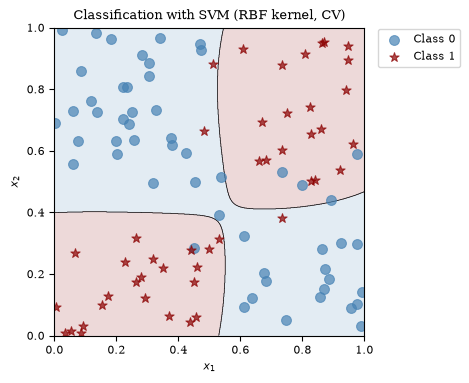

In [65]:
ax = plot_classes(X_train, y_train)
plot_decision_boundary(ax, xvalues, svm_rbf_cv)
_ = ax.set_title('Classification with SVM (RBF kernel, CV)')

We now extend the earlier comparison with the tuned RBF SVM. The ranking describes this
particular training sample and may change with a different draw.

In [66]:
# Copy the main comparison and add the SVM selected by cross-validation
models_with_svm = models.copy()
models_with_svm['SVM, RBF CV'] = svm_rbf_cv

# Report the same four metrics for the training and test samples
samples = {'Training': (X_train, y_train), 'Test': (X_test, y_test)}
for sample_name, (X_sample, y_sample) in samples.items():
    print(f'\n{sample_name} sample:')
    header = (
        f'{"Model":<25} {"Accuracy":>10} {"Precision":>10} {"Recall":>10} '
        f'{"F1 score":>10}'
    )
    if sample_name == 'Training':
        header += f' {"CV ACC":>10}'
    print(header)
    for name, model in models_with_svm.items():
        y_sample_pred = model.predict(X_sample)
        acc = accuracy_score(y_sample, y_sample_pred)
        pre = precision_score(y_sample, y_sample_pred)
        rec = recall_score(y_sample, y_sample_pred)
        f1 = f1_score(y_sample, y_sample_pred)

        row = f'{name:<25} {acc:10.3f} {pre:10.3f} {rec:10.3f} {f1:10.3f}'
        if sample_name == 'Training':
            cv_text = f'{model.best_score_:.3f}'
            row += f' {cv_text:>10}'
        print(row)


Training sample:
Model                       Accuracy  Precision     Recall   F1 score     CV ACC
Logistic, CV                   0.930      0.915      0.935      0.925      0.910
Decision tree, CV              0.940      1.000      0.870      0.930      0.800
Random forest, CV              1.000      1.000      1.000      1.000      0.880
SVM, RBF CV                    0.920      0.896      0.935      0.915      0.930

Test sample:
Model                       Accuracy  Precision     Recall   F1 score
Logistic, CV                   0.842      0.874      0.796      0.833
Decision tree, CV              0.803      0.896      0.684      0.776
Random forest, CV              0.831      0.869      0.777      0.820
SVM, RBF CV                    0.842      0.854      0.824      0.838


The tuned SVM achieves similar test accuracy to logistic regression,
with higher recall and a slightly higher F1 score in this example.

***
## List of functions and classes used in this lecture

The following list contains the central functions and classes covered in this lecture.
Each name is linked to the official API documentation, which you can consult for more
details regarding arguments and return values. The "go to section" links lead to the
relevant section in this notebook.

### Scikit-learn classification models

- [`LogisticRegression()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html): Class for fitting logistic regression models. [[go to section]](#fitting-the-logistic-regression-model)
- [`LogisticRegressionCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegressionCV.html): Class for fitting logistic regression models with built-in cross-validation. [[go to section]](#Dedicated-cross-validation-with-LogisticRegressionCV)
- [`DecisionTreeClassifier()`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html): Class for fitting decision tree classifiers. [[go to section]](#decision-trees)
- [`RandomForestClassifier()`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html): Class for fitting random forest classifiers. [[go to section]](#random-forest)
- [`SVC()`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html): Class for fitting support vector machine classifiers. [[go to section]](#support-vector-machines-svm)

### Scikit-learn metrics and visualization

- [`accuracy_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html):
  Function for computing classification accuracy.
  [[go to section]](#assessing-model-accuracy)
- [`precision_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.precision_score.html):
  Function for computing precision. [[go to section]](#assessing-model-accuracy)
- [`recall_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.recall_score.html):
  Function for computing recall. [[go to section]](#assessing-model-accuracy)
- [`f1_score()`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html):
  Function for computing the F1 score. [[go to section]](#assessing-model-accuracy)
- [`ConfusionMatrixDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_predictions): Class for visualizing confusion matrices. [[go to section]](#assessing-model-accuracy)
- [`plot_tree()`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.plot_tree.html): Function for visualizing decision trees. [[go to section]](#decision-trees)

### Scikit-learn model selection and evaluation

- [`train_test_split()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html): Function for demonstrating a stratified training and test split. [[go to section]](#training-and-test-samples)

- [`GridSearchCV()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html): Class for performing grid search with cross-validation. [[go to section]](#cross-validating-the-penalty-term)
- [`StratifiedKFold()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html): Class for defining folds with approximately equal class proportions. [[go to section]](#cross-validating-the-penalty-term)
- [`validation_curve()`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html): Function for computing validation curves. [[go to section]](#validation-curves)